In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model

In [2]:
# If needed:
# %pip install requests pandas numpy openpyxl

from pathlib import Path
from datetime import datetime
from shutil import copy2
import os

import requests
import numpy as np
import pandas as pd
from openpyxl import load_workbook


# 1. Configuration
LATITUDE = 23.0031
LONGITUDE = 71.3923
LOCAL_TIMEZONE = "Asia/Kolkata"
DNI_COLUMN = "OM-DNI (W/m2)"

DATA_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
    r"\OneDrive_2026-08-26\Solar Profile Dataset\Summer"
)

FILES = {
    "Train": DATA_DIR / "Summer_Train.xlsx",
    "Validation": DATA_DIR / "Summer_Val.xlsx",
    "Test": DATA_DIR / "Summer_Test.xlsx",
}

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
backup_dir = DATA_DIR / "Backups" / f"Before_DNI_{run_id}"
dni_dir = DATA_DIR / "OpenMeteo_DNI"
dni_dir.mkdir(parents=True, exist_ok=True)


# 2. Read and validate timestamps without changing existing rows.
workbooks = {}
timestamps_by_split = {}
sheets = {}

for split, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(path)

    workbook = load_workbook(path)
    sheet = workbook.worksheets[0]  # Same first sheet used by read_excel().
    headers = [cell.value for cell in sheet[1]]

    if headers.count("TimeStamp") != 1:
        raise ValueError(f"{path.name}: expected one TimeStamp column.")

    if headers.count(DNI_COLUMN) > 1:
        raise ValueError(f"{path.name}: duplicate {DNI_COLUMN} columns.")

    time_column = headers.index("TimeStamp") + 1
    times = pd.DatetimeIndex(pd.to_datetime(
        [
            sheet.cell(row, time_column).value
            for row in range(2, sheet.max_row + 1)
        ],
        errors="raise",
    ))

    if times.empty or times.hasnans or times.has_duplicates:
        raise ValueError(f"{path.name}: empty, missing or duplicate timestamps.")

    if times.tz is not None:
        raise ValueError(f"{path.name}: expected naive local IST timestamps.")

    if not times.equals(times.floor("15min")):
        raise ValueError(f"{path.name}: timestamps are off the 15-minute grid.")

    expected_ranges = {
        "Train": ("2026-02-15", "2026-05-09"),
        "Validation": ("2026-05-10", "2026-06-07"),
        "Test": ("2026-06-08", "2026-06-14"),
    }
    start, end = expected_ranges[split]

    expected = pd.date_range(
        start, pd.Timestamp(end) + pd.Timedelta(hours=23, minutes=45),
        freq="15min",
    )

    # The original test workbook may still contain June 3–7.
    # Preserve these rows if present; prediction code selects June 8–14.
    original_test_grid = pd.date_range(
        "2026-06-03", "2026-06-14 23:45", freq="15min"
    )
    valid_grid = times.sort_values().equals(expected)

    if split == "Test":
        valid_grid = valid_grid or times.sort_values().equals(
            original_test_grid
        )

    if not valid_grid:
        raise ValueError(f"{path.name}: unexpected date range or missing blocks.")

    workbooks[split] = workbook
    sheets[split] = sheet
    timestamps_by_split[split] = times


# 3. Download hourly historical DNI in UTC.
# Extra boundary days ensure coverage after timezone conversion.
params = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": "2026-02-14",
    "end_date": "2026-06-15",
    "hourly": "direct_normal_irradiance",
    "models": "era5",
    "timezone": "UTC",
}

response = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params=params,
    timeout=180,
)
response.raise_for_status()
payload = response.json()

if payload.get("error"):
    raise RuntimeError(payload.get("reason", "Open-Meteo API error."))

hourly_end_utc = pd.DatetimeIndex(pd.to_datetime(
    payload["hourly"]["time"], utc=True
))
hourly_values = np.asarray(
    payload["hourly"]["direct_normal_irradiance"],
    dtype=np.float64,
)

if (
    len(hourly_end_utc) != len(hourly_values)
    or not np.isfinite(hourly_values).all()
    or np.any(hourly_values < 0)
):
    raise ValueError("API returned invalid or missing DNI.")

if (
    hourly_end_utc.has_duplicates
    or not hourly_end_utc.is_monotonic_increasing
    or not np.all(np.diff(hourly_end_utc.asi8) == pd.Timedelta(hours=1).value)
):
    raise ValueError("API hourly timestamps are not continuous.")

# Each API value describes [timestamp - 1 hour, timestamp).
hourly_start_local = (
    (hourly_end_utc - pd.Timedelta(hours=1))
    .tz_convert(LOCAL_TIMEZONE)
    .tz_localize(None)
)

# Preserve the exact API response and request for reproducibility.
import json

with open(dni_dir / f"Summer_DNI_API_{run_id}.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "request": params,
            "response": payload,
            "mapping": "Preceding-hour mean assigned to contained 15-minute blocks",
            "local_timezone": LOCAL_TIMEZONE,
        },
        f,
        indent=2,
    )


# 4. Map DNI to every existing Excel timestamp.
mapped_values = {}

for split, times in timestamps_by_split.items():
    positions = hourly_start_local.get_indexer(times, method="pad")

    if np.any(positions < 0):
        raise ValueError(f"{split}: DNI does not cover the first timestamp.")

    interval_starts = hourly_start_local[positions]
    block_ends = times + pd.Timedelta(minutes=15)
    interval_ends = interval_starts + pd.Timedelta(hours=1)

    if np.any(times < interval_starts) or np.any(block_ends > interval_ends):
        raise ValueError(f"{split}: a block is outside its hourly DNI interval.")

    mapped_values[split] = hourly_values[positions]


# 5. Back up ALL originals before updating any workbook.
backup_dir.mkdir(parents=True, exist_ok=False)

for path in FILES.values():
    copy2(path, backup_dir / path.name)


# 6. Stage all updated workbooks, preserving other sheets and cells.
staged_paths = {}

for split, path in FILES.items():
    workbook = workbooks[split]
    sheet = sheets[split]
    headers = [cell.value for cell in sheet[1]]

    if DNI_COLUMN in headers:
        dni_column_index = headers.index(DNI_COLUMN) + 1
    else:
        dni_column_index = sheet.max_column + 1
        sheet.cell(1, dni_column_index, DNI_COLUMN)

    for row, value in enumerate(mapped_values[split], start=2):
        sheet.cell(row, dni_column_index, float(value))

    staged_path = path.with_name(f"{path.stem}_DNI_pending_{run_id}.xlsx")
    workbook.save(staged_path)
    workbook.close()
    staged_paths[split] = staged_path


# 7. Replace originals and export matching DNI CSVs.
for split, path in FILES.items():
    try:
        os.replace(staged_paths[split], path)
    except PermissionError:
        raise PermissionError(
            f"Close {path.name} in Excel and rerun this cell. "
            f"Original backups are in {backup_dir}. "
            "Some preceding files may already have been updated."
        ) from None

    dni_frame = pd.DataFrame({
        "TimeStamp": timestamps_by_split[split],
        DNI_COLUMN: mapped_values[split],
    }).sort_values("TimeStamp")

    csv_path = dni_dir / f"Summer_{split}_DNI.csv"
    dni_frame.to_csv(
        csv_path, index=False, date_format="%Y-%m-%d %H:%M"
    )

    print(f"{split}: added DNI to {len(dni_frame):,} rows")
    print(f"  Excel: {path}")
    print(f"  CSV:   {csv_path}")

print(f"\nBackups: {backup_dir}")
print("\nReload train, validation, test and test_with_history before S4.")

Train: added DNI to 8,064 rows
  Excel: C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Summer\Summer_Train.xlsx
  CSV:   C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Summer\OpenMeteo_DNI\Summer_Train_DNI.csv
Validation: added DNI to 2,784 rows
  Excel: C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Summer\Summer_Val.xlsx
  CSV:   C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Summer\OpenMeteo_DNI\Summer_Validation_DNI.csv
Test: added DNI to 672 rows
  Excel: C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Summer\Summer_Test.xlsx
  CSV:   C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Summer\OpenMeteo_DNI\Summer_Test_DNI.csv

Backups: C:\Users\yashs\Desktop\ML\Project Fall 2026\OneDrive_2026-08-26\Solar Profile Dataset\Summer\Backups\Before_DNI_20261112_18

In [7]:
# Replace:
# if set(validation.columns) != set(test.columns):
#     raise ValueError("Validation and test column names differ.")

required_columns = [
    "TimeStamp",
    "Act. Power (MW)",
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]


def standardize_required_columns(data, split_name):
    data = data.copy()

    def normalize(name):
        return " ".join(str(name).split())

    lookup = {}
    for column in data.columns:
        lookup.setdefault(normalize(column), []).append(column)

    rename_map = {}

    for required in required_columns:
        matches = lookup.get(normalize(required), [])

        if not matches:
            raise ValueError(
                f"{split_name}: missing required column {required!r}.\n"
                f"Available columns: {data.columns.tolist()}"
            )

        if len(matches) != 1:
            raise ValueError(
                f"{split_name}: ambiguous columns for {required!r}: {matches}"
            )

        rename_map[matches[0]] = required

    return data.rename(columns=rename_map)


train = standardize_required_columns(train, "Training")
validation = standardize_required_columns(validation, "Validation")
test = standardize_required_columns(test, "Test")

print("All required Summer S4 columns are present.")

All required Summer S4 columns are present.


In [ ]:
# Replace:
# if set(validation.columns) != set(test.columns):
#     raise ValueError("Validation and test column names differ.")

required_columns = [
    "TimeStamp",
    "Act. Power (MW)",
    "W-MODT- (°C)",
    "W-GHI (W/m2)",
    "W-AMBT (°C)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]


def standardize_required_columns(data, split_name):
    data = data.copy()
import numpy as np
import pandas as pd

REVISION_LENGTHS = {
    'R0': 32,
    'R1': 50,
    'R2': 64,
    'R3': 82,
}
BASE_FUTURE_EXOG_COLUMNS = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
]

# DNI is the only additional variable selected for S4.
EXTRA_FUTURE_EXOG_COLUMNS = [
    "OM-DNI (W/m2)",
]

FUTURE_EXOG_COLUMNS = (
    BASE_FUTURE_EXOG_COLUMNS + EXTRA_FUTURE_EXOG_COLUMNS
)
SELECTED_FUTURE_EXOG_COLUMNS = FUTURE_EXOG_COLUMNS.copy()

TARGET_LENGTH = 96
PADDED_INPUT_LENGTH = 82
BLOCKS_PER_DAY = 96
POWER_COLUMN = 'Act. Power (MW)'
MASK_VALUE = -1.0  # History padding only; separate from the night mask.

# Past exogenous: wind speed excluded.
PAST_EXOG_COLUMNS = [
    'W-MODT- (°C)',
    'W-GHI (W/m2)',
    'W-AMBT (°C)',
    'W-WDIR-   (Degree)',
]

# REQUIRED: insert the exact selected future feature names.
# FUTURE_EXOG_COLUMNS = [
#     # Your selected future exogenous columns here.
# ]

# if not FUTURE_EXOG_COLUMNS:
#     raise ValueError(
#         "Fill FUTURE_EXOG_COLUMNS with your feature-selection results."
#     )

if POWER_COLUMN in FUTURE_EXOG_COLUMNS:
    raise ValueError("Future actual power cannot be an input feature.")

HISTORY_COLUMNS = [POWER_COLUMN] + PAST_EXOG_COLUMNS


def create_revision_samples(split):
    """
    Create within-split D -> D+1 samples.

    X:        unpadded past power + past exogenous
    X_future: selected D+1 exogenous, all 96 blocks
    y:        D+1 power, all 96 blocks

    No scaling, padding, or night masking at this stage.
    """
    data = split.copy()
    data['TimeStamp'] = pd.to_datetime(data['TimeStamp'], errors='raise')

    if data['TimeStamp'].isna().any():
        raise ValueError("TimeStamp contains missing values.")

    data['Date'] = data['TimeStamp'].dt.date

    # Match headers despite extra spaces in Excel column names.
    def normalize(name):
        return ' '.join(str(name).split())

    column_lookup = {}
    for col in data.columns:
        key = normalize(col)
        if key in column_lookup:
            raise ValueError(f"Ambiguous column headers: {key}")
        column_lookup[key] = col

    def resolve_columns(names):
        missing = [
            name for name in names if normalize(name) not in column_lookup
        ]
        if missing:
            raise ValueError(f"Missing columns: {missing}")
        return [column_lookup[normalize(name)] for name in names]

    history_cols = resolve_columns(HISTORY_COLUMNS)
    future_cols = resolve_columns(FUTURE_EXOG_COLUMNS)
    power_col = resolve_columns([POWER_COLUMN])[0]

    day_groups = {
        day: frame.sort_values('TimeStamp')
        for day, frame in data.groupby('Date', sort=True)
    }

    def is_complete_day(day, frame):
        expected = pd.date_range(
            start=pd.Timestamp(day),
            periods=BLOCKS_PER_DAY,
            freq='15min',
        )
        return pd.DatetimeIndex(frame['TimeStamp']).equals(expected)

    X, X_future, y = [], [], []
    revision_labels, sample_dates = [], []
    revision_sample_indices = {
        revision: [] for revision in REVISION_LENGTHS
    }
    skipped_pairs = 0

    for day, day_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        next_day_data = day_groups.get(next_day)

        # Never borrow the next day from another split.
        if next_day_data is None:
            continue

        if not (
            is_complete_day(day, day_data)
            and is_complete_day(next_day, next_day_data)
        ):
            skipped_pairs += 1
            continue

        day_history = day_data[history_cols].to_numpy(dtype=np.float32)
        future_exog = next_day_data[future_cols].to_numpy(dtype=np.float32)
        target_power = next_day_data[power_col].to_numpy(dtype=np.float32)

        # Only the first 82 history blocks can enter the model.
        for name, values in (
            ('history', day_history[:PADDED_INPUT_LENGTH]),
            ('future exogenous', future_exog),
            ('target power', target_power),
        ):
            if not np.isfinite(values).all():
                raise ValueError(
                    f"Missing/non-finite {name}: {day} -> {next_day}"
                )

        for revision, sequence_length in REVISION_LENGTHS.items():
            sample_index = len(X)

            X.append(day_history[:sequence_length].copy())
            X_future.append(future_exog.copy())
            y.append(target_power.copy())

            revision_labels.append(revision)
            sample_dates.append(next_day)
            revision_sample_indices[revision].append(sample_index)

    if not X:
        raise ValueError("No complete consecutive D -> D+1 pairs found.")

    if skipped_pairs:
        print(f"Skipped {skipped_pairs} incomplete D -> D+1 pairs.")

    return (
        X,
        np.stack(X_future),
        np.stack(y),
        np.asarray(revision_labels),
        revision_sample_indices,
        np.asarray(sample_dates),
    )


(
    X_train, X_future_train, y_train,
    revision_labels_train, revision_indices_train, dates_train,
) = create_revision_samples(train)

(
    X_validation, X_future_validation, y_validation,
    revision_labels_validation, revision_indices_validation,
    dates_validation,
) = create_revision_samples(validation)

# Include the day before the test period as input history only.
test_dates = sorted(
    pd.to_datetime(test['TimeStamp']).dt.date.unique()
)

history_date = (
    pd.Timestamp(test_dates[0]) - pd.Timedelta(days=1)
).date()

test_history = validation.loc[
    pd.to_datetime(validation['TimeStamp']).dt.date == history_date
].copy()

if len(test_history) != BLOCKS_PER_DAY:
    raise ValueError(
        f"Expected 96 history blocks for {history_date}, "
        f"found {len(test_history)}."
    )

test_with_history = pd.concat(
    [test_history, test], ignore_index=True
).sort_values('TimeStamp')

(
    X_test, X_future_test, y_test,
    revision_labels_test, revision_indices_test, dates_test,
) = create_revision_samples(test_with_history)

assert len(test_dates) == 7, "Expected seven test dates."
assert set(dates_test) == set(test_dates), (
    "Some test dates are missing; check timestamps and completeness."
)

for revision in REVISION_LENGTHS:
    assert len(revision_indices_test[revision]) == 7

print("Test: 7 target days × 4 revisions = 28 samples")

revision_info = {
    'lengths': REVISION_LENGTHS,
    'train': revision_indices_train,
    'validation': revision_indices_validation,
    'test': revision_indices_test,
}

# Night-mask source: one target profile per training date.
# Prevents counting the same day four times because of R0–R3.
_, unique_train_day_indices = np.unique(dates_train, return_index=True)
nightmask_training_power = y_train[unique_train_day_indices].copy()

for split_name, X_split, future_split, y_split, labels in (
    ('Train', X_train, X_future_train, y_train, revision_labels_train),
    (
        'Validation', X_validation, X_future_validation,
        y_validation, revision_labels_validation,
    ),
    ('Test', X_test, X_future_test, y_test, revision_labels_test),
):
    revision_counts = dict(zip(*np.unique(labels, return_counts=True)))

    print(f'{split_name}: {len(labels)} samples')
    print(f'  Raw history shapes: {[x.shape for x in X_split[:4]]}')
    print(f'  Future exogenous shape: {future_split.shape}')
    print(f'  Target shape: {y_split.shape}')
    print(f'  Revision counts: {revision_counts}')
  
    def normalize(name):
        return " ".join(str(name).split())

    lookup = {}
    for column in data.columns:
        lookup.setdefault(normalize(column), []).append(column)

    rename_map = {}

    for required in required_columns:
        matches = lookup.get(normalize(required), [])

        if not matches:
            raise ValueError(
                f"{split_name}: missing required column {required!r}.\n"
                f"Available columns: {data.columns.tolist()}"
            )

        if len(matches) != 1:
            raise ValueError(
                f"{split_name}: ambiguous columns for {required!r}: {matches}"
            )

        rename_map[matches[0]] = required

    required_columns = [
        "TimeStamp",
        "Act. Power (MW)",
        "W-MODT- (°C)",
        "W-GHI (W/m2)",
        "W-AMBT (°C)",
        "W-WDIR-   (Degree)",
        "W-WSPD (m/s)",
        "OM-DNI (W/m2)",
    ]


    def standardize_required_columns(data, split_name):
        data = data.copy()

        def normalize(name):
            return " ".join(str(name).split())

        lookup = {}
        for column in data.columns:
            lookup.setdefault(normalize(column), []).append(column)

        rename_map = {}

        for required in required_columns:
            matches = lookup.get(normalize(required), [])

            if not matches:
                raise ValueError(
                    f"{split_name}: missing required column {required!r}.\n"
                    f"Available columns: {data.columns.tolist()}"
                )

            if len(matches) != 1:
                raise ValueError(
                    f"{split_name}: ambiguous columns for {required!r}: {matches}"
                )

            rename_map[matches[0]] = required

        return data.rename(columns=rename_map)


    train = standardize_required_columns(train, "Training")
    validation = standardize_required_columns(validation, "Validation")
    test = standardize_required_columns(test, "Test")

    print("All required Summer S4 columns are present.")


train = standardize_required_columns(train, "Training")
validation = standardize_required_columns(validation, "Validation")
test = standardize_required_columns(test, "Test")

print("All required Summer S4 columns are present.")

Test: 7 target days × 4 revisions = 28 samples


SyntaxError: 'return' outside function (2931617951.py, line 294)

In [5]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


In [6]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping


def build_model(n_future_exog):
    """
    n_future_exog: number of future weather variables being tested.
    Two time channels are always included.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name='encoder_input',
    )

    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name='encoder_masking',
    )(encoder_input)

    encoder_context = SimpleRNN(
        64,
        name='encoder_rnn',
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name='future_input',
    )

    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name='repeat_context',
    )(encoder_context)

    decoder_input = Concatenate(
        axis=-1,
        name='decoder_features',
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name='decoder_rnn',
    )(decoder_input)

    block_predictions = TimeDistributed(
        Dense(1),
        name='block_prediction',
    )(decoder_sequence)

    forecast = Reshape(
        (TARGET_LENGTH,),
        name='forecast',
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


print("Model builder ready for future-feature selection.")

Model builder ready for future-feature selection.


In [7]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping


# 1. Scenario 4 benchmark configuration
SCENARIO = "S4"
SEED = 42
BATCH_SIZE = 16
MAX_EPOCHS = 150

benchmark_features = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]

source_columns = list(FUTURE_EXOG_COLUMNS)
missing = set(benchmark_features) - set(source_columns)

if missing:
    raise ValueError(f"Missing future weather columns: {sorted(missing)}")

selected_indices = [
    source_columns.index(column)
    for column in benchmark_features
] + [len(source_columns), len(source_columns) + 1]


# 2. Prepare four weather channels plus time sine and cosine
def select_s4_future(full_inputs):
    full_inputs = np.asarray(full_inputs)

    if (
        full_inputs.ndim != 3
        or full_inputs.shape[1:] != (96, len(source_columns) + 2)
    ):
        raise ValueError(f"Unexpected future input shape: {full_inputs.shape}")

    return full_inputs[:, :, selected_indices].astype(np.float32)


benchmark_future_train = select_s4_future(X_future_train_scaled)
benchmark_future_validation = select_s4_future(X_future_validation_scaled)
benchmark_future_test = select_s4_future(X_future_test_scaled)

for name, X, future, y in (
    ("Train", X_train_scaled, benchmark_future_train, y_train_scaled),
    (
        "Validation",
        X_validation_scaled,
        benchmark_future_validation,
        y_validation_scaled,
    ),
    ("Test", X_test_scaled, benchmark_future_test, y_test_scaled),
):
    if X.shape != (len(y), 82, 7):
        raise ValueError(f"{name}: expected history shape (samples, 82, 7).")
    if future.shape != (len(y), 96, 6):
        raise ValueError(f"{name}: expected future shape (samples, 96, 6).")
    if y.shape != (len(y), 96):
        raise ValueError(f"{name}: expected target shape (samples, 96).")
    if not all(np.isfinite(values).all() for values in (X, future, y)):
        raise ValueError(f"{name}: missing or infinite values.")

expected_pairs = pd.MultiIndex.from_product([
    pd.date_range("2026-02-08", "2026-02-14"),
    ["R0", "R1", "R2", "R3"],
])
actual_pairs = pd.MultiIndex.from_arrays([
    pd.DatetimeIndex(dates_test).normalize(),
    revision_labels_test,
])

if not actual_pairs.sort_values().equals(expected_pairs.sort_values()):
    raise ValueError("Expected all four revisions for February 8–14.")

if y_test_scaled.shape != (28, 96):
    raise ValueError("Expected 28 test samples.")


# 3. Build the fresh benchmark model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

encoder_input = layers.Input(shape=(82, 7), name="encoder_input")
masked_history = layers.Masking(
    mask_value=-1.0, name="encoder_masking"
)(encoder_input)
encoder_context = layers.SimpleRNN(
    64, name="encoder_rnn"
)(masked_history)

future_input = layers.Input(shape=(96, 6), name="future_input")
repeated_context = layers.RepeatVector(
    96, name="repeat_context"
)(encoder_context)
decoder_input = layers.Concatenate(
    axis=-1, name="decoder_features"
)([repeated_context, future_input])

decoder_sequence = layers.SimpleRNN(
    64, return_sequences=True, name="decoder_rnn"
)(decoder_input)
block_predictions = layers.TimeDistributed(
    layers.Dense(1), name="block_prediction"
)(decoder_sequence)
forecast = layers.Reshape((96,), name="forecast")(block_predictions)

benchmark_model = Model(
    inputs=[encoder_input, future_input],
    outputs=forecast,
)
benchmark_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"],
)


# 4. Measure validation passes inside fit()
class ValidationTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.validation_seconds = 0.0
        self.validation_passes = 0

    def on_test_begin(self, logs=None):
        self.validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self.validation_seconds += perf_counter() - self.validation_start
        self.validation_passes += 1


timer = ValidationTimer()
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
)


# 5. Training and validation timing
fit_start = perf_counter()

benchmark_history = benchmark_model.fit(
    [X_train_scaled, benchmark_future_train],
    y_train_scaled,
    validation_data=(
        [X_validation_scaled, benchmark_future_validation],
        y_validation_scaled,
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[early_stopping, timer],
    verbose=1,
)

fit_seconds = perf_counter() - fit_start
validation_seconds = timer.validation_seconds
training_seconds = fit_seconds - validation_seconds

validation_losses = np.asarray(
    benchmark_history.history["val_loss"], dtype=float
)
if not np.isfinite(validation_losses).all():
    raise ValueError("Nonfinite validation losses in benchmark run.")


# 6. Seven-day testing time
test_start = perf_counter()

benchmark_predictions_scaled = benchmark_model.predict(
    [X_test_scaled, benchmark_future_test],
    batch_size=BATCH_SIZE,
    verbose=0,
)

testing_seconds = perf_counter() - test_start
overall_seconds = fit_seconds + testing_seconds

if (
    benchmark_predictions_scaled.shape != (28, 96)
    or not np.isfinite(benchmark_predictions_scaled).all()
):
    raise ValueError("Invalid benchmark predictions.")


# 7. Save this run and update the S1–S4 summary
timing_dir = Path(W_TRAIN).parent.parent / "Results" / "Timing"
timing_dir.mkdir(parents=True, exist_ok=True)

run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
gpu_devices = tf.config.list_physical_devices("GPU")

record = {
    "Model": "RNN",
    "Scenario": SCENARIO,
    "Run_ID": run_id,
    "Run_Type": "Repeated training benchmark",
    "Epochs": len(benchmark_history.history["loss"]),
    "Best_Epoch": int(np.argmin(validation_losses)) + 1,
    "Batch_Size": BATCH_SIZE,
    "Training_s": training_seconds,
    "Validation_s": validation_seconds,
    "Testing_s": testing_seconds,
    "Overall_s": overall_seconds,
    "Validation_Passes": timer.validation_passes,
    "Train_Samples": len(X_train_scaled),
    "Validation_Samples": len(X_validation_scaled),
    "Test_Samples": len(X_test_scaled),
    "CPU": platform.processor(),
    "Visible_GPUs": "; ".join(
        tf.config.experimental.get_device_details(device).get(
            "device_name", device.name
        )
        for device in gpu_devices
    ) or "None",
    "TensorFlow_Version": tf.__version__,
    "OS": platform.platform(),
}

timing_row = pd.DataFrame([record])
run_path = timing_dir / f"RNN_{SCENARIO}_Timing_{run_id}.csv"
timing_row.to_csv(run_path, index=False)

pd.DataFrame(benchmark_history.history).to_csv(
    timing_dir / f"RNN_{SCENARIO}_History_{run_id}.csv",
    index=False,
)

summary_path = timing_dir / "Winter_RNN_Computation_Times.csv"

if summary_path.exists():
    summary = pd.concat(
        [pd.read_csv(summary_path), timing_row],
        ignore_index=True,
    ).drop_duplicates(["Model", "Scenario"], keep="last")
else:
    summary = timing_row

summary = summary.sort_values(["Model", "Scenario"], ignore_index=True)

try:
    summary.to_csv(summary_path, index=False)
    print(f"\nUpdated timing summary: {summary_path}")
except PermissionError:
    print("\nClose the timing summary in Excel, then run:")
    print("summary.to_csv(summary_path, index=False)")
    print(f"This run's timings are saved to: {run_path}")

print(f"\nEpochs completed: {record['Epochs']}")
print(f"Training time:   {training_seconds:.3f} seconds")
print(f"Validation time: {validation_seconds:.3f} seconds")
print(f"Testing time:    {testing_seconds:.3f} seconds")
print(f"Overall time:    {overall_seconds:.3f} seconds")


Epoch 1/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 131ms/step - loss: 0.2162 - mae: 0.3507 - val_loss: 0.0324 - val_mae: 0.1455
Epoch 2/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - loss: 0.0430 - mae: 0.1615 - val_loss: 0.0225 - val_mae: 0.1178
Epoch 3/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0197 - mae: 0.1109 - val_loss: 0.0135 - val_mae: 0.0898
Epoch 4/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0143 - mae: 0.0936 - val_loss: 0.0106 - val_mae: 0.0782
Epoch 5/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0109 - mae: 0.0807 - val_loss: 0.0090 - val_mae: 0.0716
Epoch 6/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - loss: 0.0097 - mae: 0.0756 - val_loss: 0.0081 - val_mae: 0.0675
Epoch 7/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0089 - mae: 0.0725 - val_loss: 0.0072 - val_mae: 0.0632
Epoch 8/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - loss: 0.0084 - mae: 0.0698 - val_loss: 0.0068 - val_mae: 0.0608
Epoch 9/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - 

In [13]:
from pathlib import Path
import numpy as np
import joblib
from tensorflow import keras

# Run the sample-creation and preprocessing cells before this cell.
save_dir = Path.cwd() / "scenario4_checkpoint"
state_path = save_dir / "search_state.joblib"

if not state_path.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {state_path}")

state = joblib.load(state_path)

SELECTED_FUTURE_EXOG_COLUMNS = list(state["best_columns"])

expected_selection = [
    "W-GHI (W/m2)",
    "W-WDIR-   (Degree)",
    "W-WSPD (m/s)",
    "OM-DNI (W/m2)",
]

assert SELECTED_FUTURE_EXOG_COLUMNS == expected_selection, (
    "The saved winner differs from the reported DNI model."
)

# Current weather-channel order, before the final two time channels.
source_columns = list(FUTURE_EXOG_COLUMNS)

assert list(state["past_columns"]) == list(PAST_EXOG_COLUMNS), (
    "Past-feature order differs from the saved model."
)


# Verify that the current arrays use the saved scaling.
def check_scaler(current, saved, label, saved_indices=None):
    for attribute in ("scale_", "min_"):
        current_values = np.asarray(getattr(current, attribute))
        saved_values = np.asarray(getattr(saved, attribute))

        if saved_indices is not None:
            saved_values = saved_values[saved_indices]

        assert current_values.shape == saved_values.shape, (
            f"{label}: scaler feature counts differ."
        )
        assert np.allclose(current_values, saved_values), (
            f"{label}: scaling differs from training. "
            "Recreate the arrays using the saved preprocessing."
        )


check_scaler(scaler, state["scaler"], "Power")
check_scaler(
    past_exog_scaler,
    state["past_exog_scaler"],
    "Past exogenous",
)

saved_future_columns = list(state["source_columns"])

missing_columns = [
    column for column in source_columns
    if column not in saved_future_columns
]
if missing_columns:
    raise ValueError(
        f"Current future columns absent from checkpoint: {missing_columns}"
    )

saved_indices = [
    saved_future_columns.index(column)
    for column in source_columns
]

check_scaler(
    future_exog_scaler,
    state["future_exog_scaler"],
    "Future exogenous",
    saved_indices=saved_indices,
)


# Select the four winning weather channels plus sine/cosine time.
def prepare_selected_future(full_inputs):
    assert full_inputs.ndim == 3
    assert full_inputs.shape[1:] == (
        TARGET_LENGTH,
        len(source_columns) + 2,
    )

    missing = [
        column for column in SELECTED_FUTURE_EXOG_COLUMNS
        if column not in source_columns
    ]
    if missing:
        raise ValueError(f"Missing selected future features: {missing}")

    weather_indices = [
        source_columns.index(column)
        for column in SELECTED_FUTURE_EXOG_COLUMNS
    ]
    time_indices = [
        len(source_columns),
        len(source_columns) + 1,
    ]

    selected = full_inputs[
        :, :, weather_indices + time_indices
    ].astype(np.float32)

    assert np.isfinite(selected).all()
    return selected


X_future_train_selected = prepare_selected_future(
    X_future_train_scaled
)
X_future_validation_selected = prepare_selected_future(
    X_future_validation_scaled
)
X_future_test_selected = prepare_selected_future(
    X_future_test_scaled
)

# Restore the power scaler and training-derived night mask.
scaler = state["scaler"]
night_blocks = np.asarray(state["night_blocks"], dtype=int)

assert np.all((night_blocks >= 0) & (night_blocks < TARGET_LENGTH))

# Use the filename recorded by the search, rather than hard-coding a trial.
model_path = save_dir / state["best_model_file"]

if not model_path.is_file():
    raise FileNotFoundError(f"Saved model not found: {model_path}")

model = keras.models.load_model(model_path)

assert model.input_shape == [
    (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
    (None, TARGET_LENGTH, 6),  # Four weather + two time channels.
]
assert model.output_shape == (None, TARGET_LENGTH)

for history_inputs, future_inputs in (
    (X_train_scaled, X_future_train_selected),
    (X_validation_scaled, X_future_validation_selected),
    (X_test_scaled, X_future_test_selected),
):
    assert history_inputs.shape == (
        len(future_inputs),
        PADDED_INPUT_LENGTH,
        N_HISTORY_FEATURES,
    )
    assert np.isfinite(history_inputs).all()

# Verify all seven test days have exactly one sample per revision.
test_dates_array = np.asarray(dates_test)
test_labels = np.asarray(revision_labels_test)

assert len(np.unique(test_dates_array)) == 7
assert len(test_dates_array) == len(test_labels) == len(X_test_scaled) == 28

for day in np.unique(test_dates_array):
    for revision in REVISION_LENGTHS:
        assert np.sum(
            (test_dates_array == day) & (test_labels == revision)
        ) == 1, f"Missing/duplicate sample: {day}, {revision}"

print("Scenario 4 winning model loaded — no retraining.")
print("Model:", model_path)
print("Selected future variables:", SELECTED_FUTURE_EXOG_COLUMNS)
print(f"Saved validation MAE: {state['best_mae']:.4f} MW")
print("Train future input:", X_future_train_selected.shape)
print("Validation future input:", X_future_validation_selected.shape)
print("Test future input:", X_future_test_selected.shape)
print("Test coverage: 7 days × 4 revisions = 28 samples")
print(f"Training-derived night mask: {len(night_blocks)} blocks")

model.summary()

Scenario 4 winning model loaded — no retraining.
Model: c:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\scenario4_checkpoint\trial_03.keras
Selected future variables: ['W-GHI (W/m2)', 'W-WDIR-   (Degree)', 'W-WSPD (m/s)', 'OM-DNI (W/m2)']
Saved validation MAE: 0.4358 MW
Train future input: (340, 96, 6)
Validation future input: (116, 96, 6)
Test future input: (28, 96, 6)
Test coverage: 7 days × 4 revisions = 28 samples
Training-derived night mask: 52 blocks


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 82, 7)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, 82, 7)     │          0 │ encoder_input[0]… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_3 (Any)         │ (None, 82)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_rnn         │ (None, 64)        │      4,608 │ encoder_masking[… │
│ (SimpleRNN)         │                   │            │ any_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 96, 64)    │          0 │ encoder_rnn[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_input        │ (None, 96, 6)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_features    │ (None, 96, 70)    │          0 │ repeat_context[0… │
│ (Concatenate)       │                   │            │ future_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_rnn         │ (None, 96, 64)    │      8,640 │ decoder_features… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_prediction    │ (None, 96, 1)     │         65 │ decoder_rnn[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 96)        │          0 │ block_prediction… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 39,941 (156.02 KB)

 Trainable params: 13,313 (52.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 26,628 (104.02 KB)

Forecast target dates: 2026-02-08, 2026-02-09, 2026-02-10, 2026-02-11, 2026-02-12, 2026-02-13, 2026-02-14
7 test days × 4 revisions = 28 profiles, each with 96 blocks.

 Revision  MAE (MW)  RMSE (MW)     R² Inside / all  Inside all (%) Inside / active  Inside active (%)
 Overall    0.5060     0.9189 0.9854    1964/2688         73.0655        502/1212            41.4191
      R0    0.5205     0.9284 0.9851      481/672         71.5774         115/303            37.9538
      R1    0.5559     1.0170 0.9821      478/672         71.1310         110/303            36.3036
      R2    0.4634     0.8410 0.9878      509/672         75.7440         143/303            47.1947
      R3    0.4843     0.8797 0.9866      496/672         73.8095         134/303            44.2244


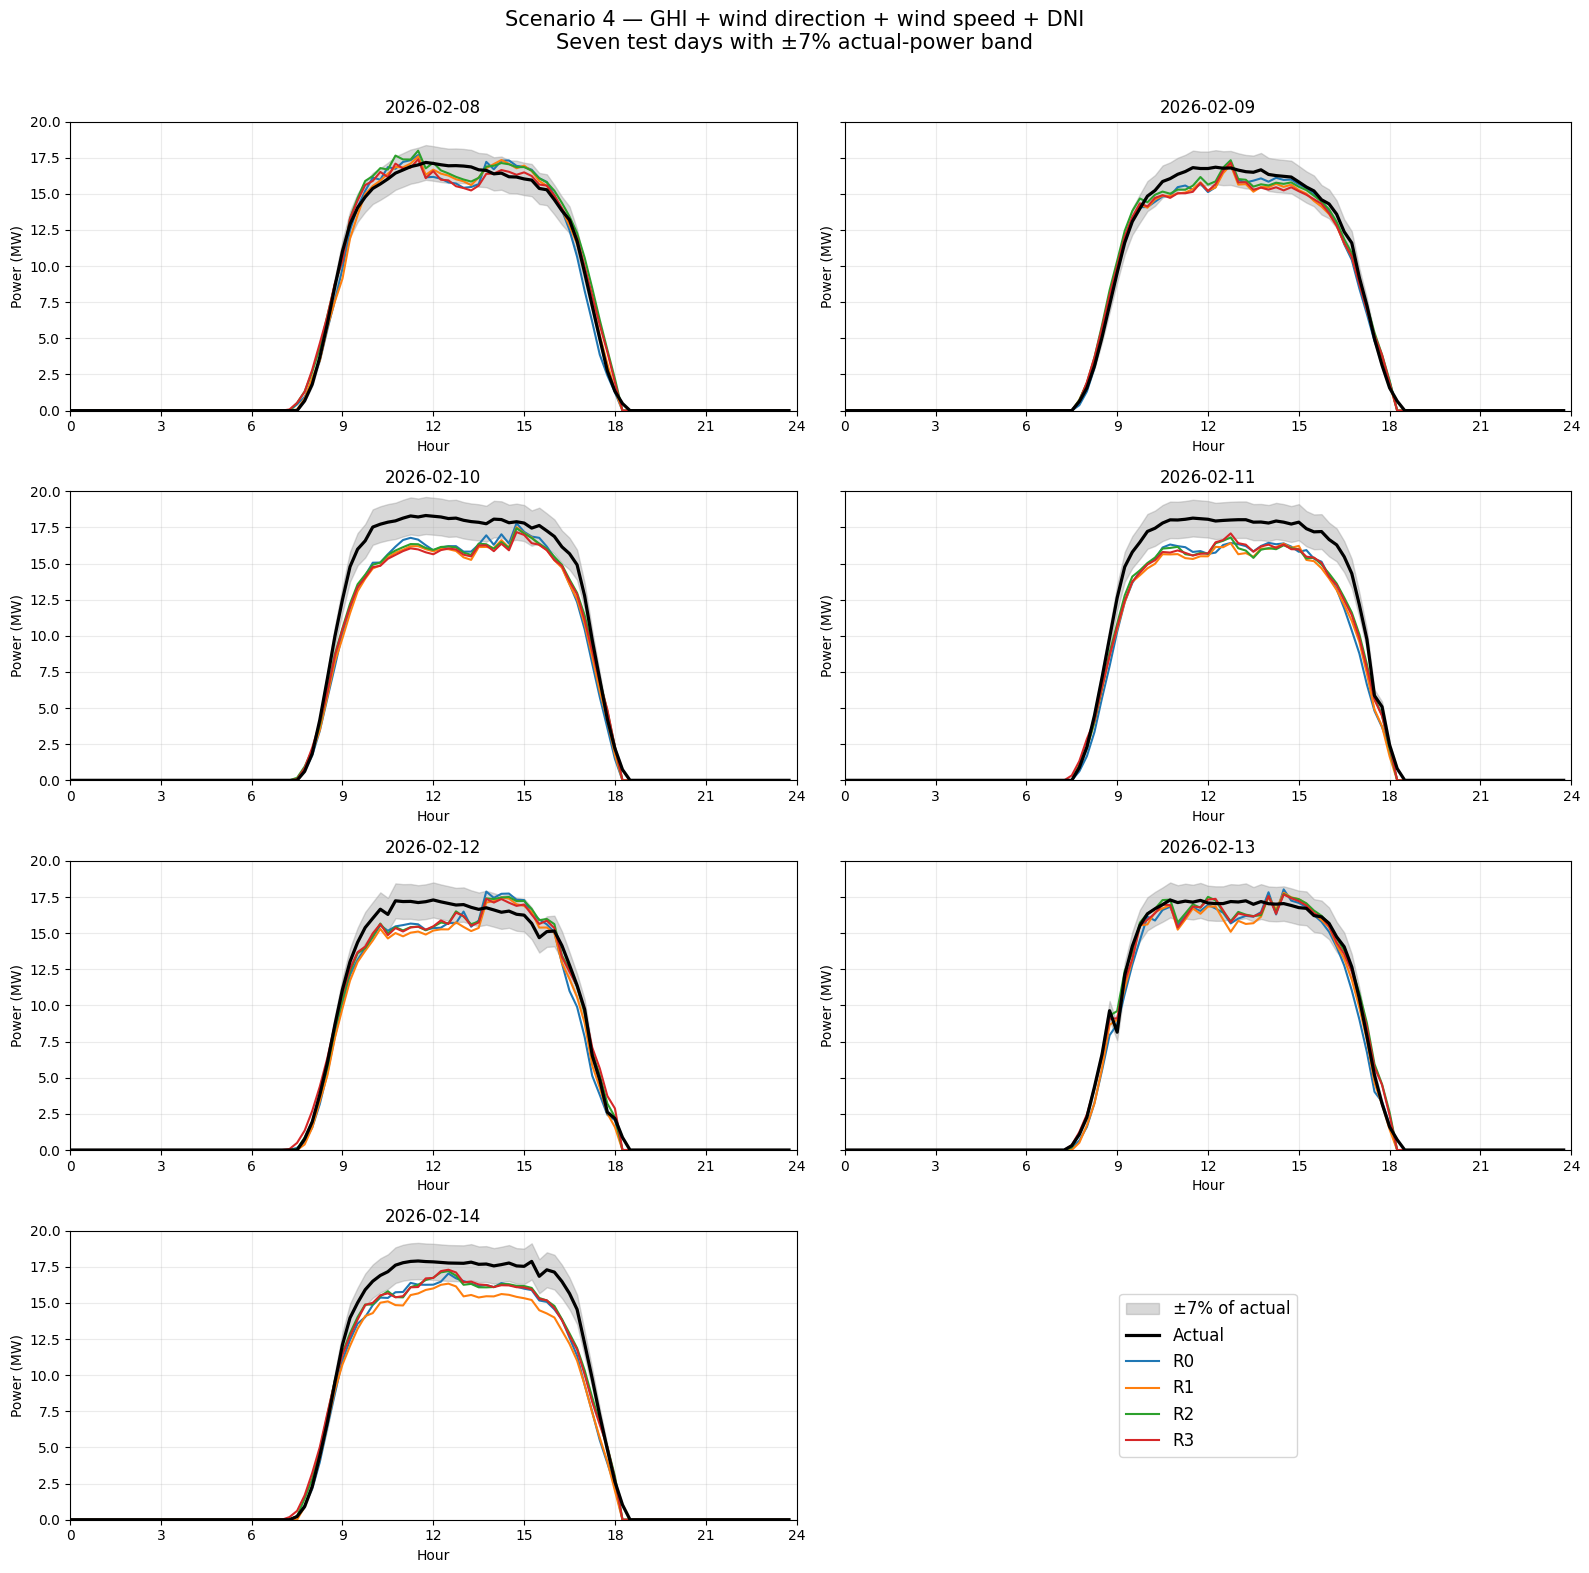

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1

# 1. Predict using the loaded model.
predictions_scaled = model.predict(
    [X_test_scaled, X_future_test_selected],
    verbose=0,
)

y_test_pred_raw = scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).reshape(y_test.shape)

# Apply the same postprocessing used during feature selection.
y_test_pred = np.maximum(y_test_pred_raw, 0.0)
y_test_pred[:, night_blocks] = 0.0

assert np.isfinite(y_test_pred).all()

test_dates_array = np.asarray(dates_test)
test_labels = np.asarray(revision_labels_test)
unique_test_dates = sorted(set(test_dates_array))

assert len(unique_test_dates) == 7, "Expected seven test days."
assert y_test_pred.shape == (7 * len(REVISION_LENGTHS), TARGET_LENGTH)

for day in unique_test_dates:
    for revision in REVISION_LENGTHS:
        count = np.sum(
            (test_dates_array == day) & (test_labels == revision)
        )
        assert count == 1, f"Missing/duplicate sample: {day}, {revision}"

print("Forecast target dates:", ", ".join(map(str, unique_test_dates)))
print("7 test days × 4 revisions = 28 profiles, each with 96 blocks.")


# 2. Metrics and counts inside ±7% of actual power.
rows = []

for revision in ["Overall", *REVISION_LENGTHS]:
    mask = (
        np.ones(len(y_test), dtype=bool)
        if revision == "Overall"
        else test_labels == revision
    )

    actual = y_test[mask].ravel()
    predicted = y_test_pred[mask].ravel()

    tolerance = BAND_FRACTION * np.abs(actual)
    inside = np.abs(predicted - actual) <= tolerance + 1e-6
    active = actual > ACTIVE_THRESHOLD_MW

    rows.append({
        "Revision": revision,
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
        "Inside / all": f"{inside.sum()}/{inside.size}",
        "Inside all (%)": 100 * inside.mean(),
        "Inside / active": f"{(inside & active).sum()}/{active.sum()}",
        "Inside active (%)": (
            100 * inside[active].mean() if active.any() else np.nan
        ),
    })

test_metrics = pd.DataFrame(rows)
print("\n", test_metrics.round(4).to_string(index=False))


# 3. Plot all seven days with a shaded ±7% band.
hours = np.arange(TARGET_LENGTH) / 4
colors = {
    "R0": "tab:blue",
    "R1": "tab:orange",
    "R2": "tab:green",
    "R3": "tab:red",
}

fig, axes = plt.subplots(
    4, 2, figsize=(16, 16), sharex=True, sharey=True
)
axes = axes.ravel()

# Include the upper band when setting plot limits.
maximum = max(
    float(np.max(y_test + BAND_FRACTION * np.abs(y_test))),
    float(y_test_pred.max()),
)
y_upper = max(20.0, np.ceil(maximum / 2.5) * 2.5)

for ax, day in zip(axes, unique_test_dates):
    day_indices = np.flatnonzero(test_dates_array == day)
    actual = y_test[day_indices[0]]

    assert np.allclose(y_test[day_indices], actual[None, :])

    tolerance = BAND_FRACTION * np.abs(actual)
    lower_band = actual - tolerance
    upper_band = actual + tolerance

    ax.fill_between(
        hours,
        lower_band,
        upper_band,
        color="gray",
        alpha=0.30,
        label="±7% of actual",
        zorder=1,
    )

    ax.plot(
        hours, actual,
        color="black",
        linewidth=2.3,
        label="Actual",
        zorder=3,
    )

    for revision in REVISION_LENGTHS:
        index = np.flatnonzero(
            (test_dates_array == day) & (test_labels == revision)
        )[0]

        ax.plot(
            hours, y_test_pred[index],
            color=colors[revision],
            linewidth=1.5,
            label=revision,
            zorder=2,
        )

    ax.set_title(str(day))
    ax.set_xlim(0, 24)
    ax.set_ylim(0, y_upper)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.set_yticks(np.arange(0, y_upper + 0.1, 2.5))
    ax.set_xlabel("Hour")
    ax.set_ylabel("Power (MW)")
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=0.25)

axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=12)

fig.suptitle(
    "Scenario 4 — GHI + wind direction + wind speed + DNI\n"
    "Seven test days with ±7% actual-power band",
    fontsize=15,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()